<a href="https://colab.research.google.com/github/varsha-0110/Code-Station/blob/main/Stock_Price_Prediction_ARIMA_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stock Price Prediction: Naive vs ARIMA vs LSTM vs ARIMA-LSTM Hybrid

Predicts the **next-day closing price** of a stock using four models and compares them fairly on the same test period.

| Model | Idea |
|---|---|
| **Naive baseline** | Tomorrow's price = today's price |
| **ARIMA** | Classical linear time-series model (walk-forward, one step ahead) |
| **LSTM** | Neural network on the previous 30 days of price |
| **ARIMA-LSTM hybrid** | ARIMA predicts the linear part, an LSTM learns the ARIMA *residuals*, and the two are added |

**Improvements over the first version:** the scaler is fit on training data only (no leakage), a time-based validation split with best-checkpoint selection is used, every model is scored on the same test days, and a naive baseline is included.

> This is a learning project, **not financial advice**.

Change the settings in the second cell (ticker, window, ARIMA order, etc.) and use **Runtime → Run all**.

## 1. Setup and settings

In [1]:
import sys, subprocess, warnings, copy
try:
    import yfinance, statsmodels
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "yfinance", "statsmodels"])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore")

# ---------------- Settings you can change ----------------
TICKER = "AAPL"
START = "2020-01-01"
TRAIN_FRAC = 0.8          # first 80% of days = train, last 20% = test (time-based split)
WINDOW = 30               # LSTM looks at the previous 30 days

AUTO_ARIMA_ORDER = True   # pick (p,1,q) by lowest AIC on the training data
ARIMA_ORDER = (5, 1, 0)   # used only if AUTO_ARIMA_ORDER is False
REFIT_EVERY = 50          # re-estimate ARIMA parameters every N test days (faster than every day)

HIDDEN, LAYERS = 32, 2
EPOCHS, LR, BATCH = 100, 1e-3, 64
SEED = 42
# ---------------------------------------------------------

np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


## 2. Download data and split by time

AAPL: 1717 trading days  (2020-01-02 to 2026-10-30)
Train: 1373 days   Test: 344 days (from 2025-06-20)


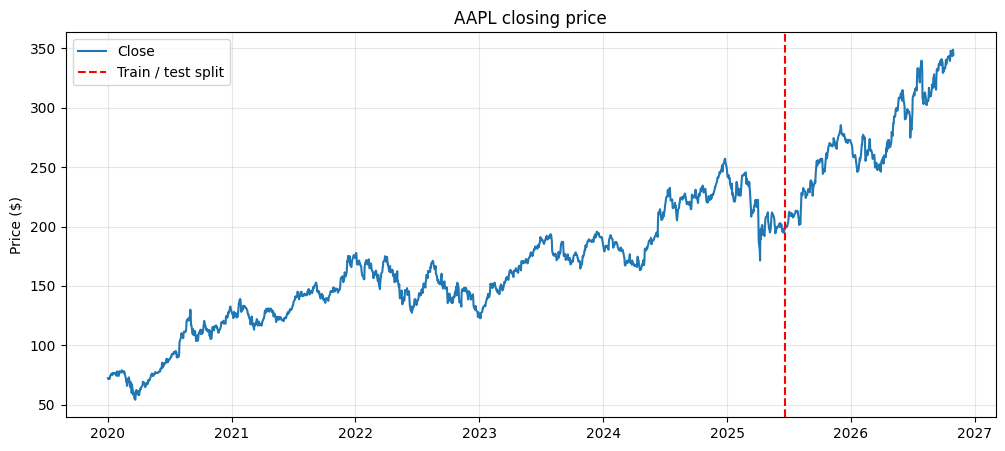

In [2]:
raw = yf.download(TICKER, start=START, auto_adjust=True, progress=False)
close = raw["Close"]
if isinstance(close, pd.DataFrame):      # newer yfinance returns a one-column DataFrame
    close = close.iloc[:, 0]
close = close.dropna()

prices = close.values.astype(float)
dates = close.index
n = len(prices)

split = int(TRAIN_FRAC * n)              # index of the first test day
train_prices = prices[:split]
test_idx = np.arange(split, n)           # every model predicts these exact days
y_true = prices[test_idx]

print(f"{TICKER}: {n} trading days  ({dates[0].date()} to {dates[-1].date()})")
print(f"Train: {split} days   Test: {n - split} days (from {dates[split].date()})")

plt.figure(figsize=(12, 5))
plt.plot(dates, prices, label="Close")
plt.axvline(dates[split], color="red", linestyle="--", label="Train / test split")
plt.title(f"{TICKER} closing price")
plt.ylabel("Price ($)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## 3. Evaluation helper and naive baseline

Every model must beat **"tomorrow = today"** to be worth anything. *Direction accuracy* is how often the model correctly predicts whether the price goes up or down versus the previous day.

In [3]:
def evaluate(name, pred, with_direction=True):
    prev = prices[test_idx - 1]
    moved = pred != prev                       # days where the model actually called a direction
    if with_direction and moved.any():
        direction = np.mean(np.sign(pred[moved] - prev[moved]) == np.sign(y_true[moved] - prev[moved])) * 100
    else:
        direction = np.nan
    return {
        "Model": name,
        "RMSE ($)": np.sqrt(mean_squared_error(y_true, pred)),
        "MAE ($)": mean_absolute_error(y_true, pred),
        "MAPE (%)": np.mean(np.abs((y_true - pred) / y_true)) * 100,
        "Direction acc. (%)": direction,
    }

naive_pred = prices[test_idx - 1]
results = [evaluate("Naive (yesterday's price)", naive_pred, with_direction=False)]
pd.DataFrame(results).round(3)

,Model,RMSE ($),MAE ($),MAPE (%),Direction acc. (%)
0,Naive (yesterday's price),4.219,2.979,1.081,NaN


## 4. ARIMA (walk-forward, one step ahead)

Prices are non-stationary, so we use `d = 1` (differencing once). The `(p, q)` orders are chosen by AIC on the **training data only**.
Then for each test day, ARIMA forecasts one day ahead, sees the real price, and moves on. This is the same information the LSTM gets.

**Heads-up:** for many stocks the lowest-AIC choice is `(0, 1, 0)`, which is a random walk and is *identical* to the naive baseline. If that happens, ARIMA and Naive will show the same scores. That is a legitimate result (it says there is little linear structure to exploit), and it makes the LSTM / hybrid comparison more interesting. To force a richer model, set `AUTO_ARIMA_ORDER = False` and pick e.g. `(5, 1, 0)`.

In [4]:
# ---- choose the (p, 1, q) order on training data only ----
if AUTO_ARIMA_ORDER:
    best = None
    for p in range(0, 4):
        for q in range(0, 3):
            try:
                aic = ARIMA(train_prices, order=(p, 1, q)).fit().aic
            except Exception:
                continue
            if best is None or aic < best[0]:
                best = (aic, (p, 1, q))
    order = best[1]
else:
    order = ARIMA_ORDER
print("ARIMA order used:", order)

# ---- fit on train, then walk forward through the test period ----
arima_res = ARIMA(train_prices, order=order).fit()
train_fitted = arima_res.fittedvalues            # in-sample one-step predictions (used for residuals)

arima_pred = np.zeros(len(test_idx))
res = arima_res
for k, t in enumerate(test_idx):
    arima_pred[k] = res.forecast(1)[0]            # predict day t using data up to t-1
    if (k + 1) % REFIT_EVERY == 0:
        res = ARIMA(prices[:t + 1], order=order).fit()          # occasional full re-fit
    else:
        res = res.append(prices[t:t + 1], refit=False)          # cheap update with the true price
arima_final = res                                  # has seen every day; used for the next-day forecast

results.append(evaluate("ARIMA", arima_pred))
pd.DataFrame(results).round(3)

ARIMA order used: (0, 1, 0)


,Model,RMSE ($),MAE ($),MAPE (%),Direction acc. (%)
0,Naive (yesterday's price),4.219,2.979,1.081,NaN
1,ARIMA,4.219,2.979,1.081,100.0


## 5. LSTM building blocks

A reusable model, window builder and training loop (mini-batches, a time-based validation set, and the best checkpoint is kept).

In [5]:
class LSTMNet(nn.Module):
    def __init__(self, input_dim=1, hidden_dim=HIDDEN, num_layers=LAYERS):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])


def make_windows(series, window):
    """X[i] = the previous `window` values, y[i] = the next value, tgt[i] = index of that next value."""
    X, y, tgt = [], [], []
    for t in range(window, len(series)):
        X.append(series[t - window:t]); y.append(series[t]); tgt.append(t)
    return np.array(X)[..., None], np.array(y)[:, None], np.array(tgt)


def to_t(a):
    return torch.tensor(a, dtype=torch.float32, device=device)


def fit_lstm(X, y, tgt, train_end, val_frac=0.15, name="LSTM"):
    """Train on windows whose target is before `train_end`; the last val_frac of them is a validation set."""
    m = tgt < train_end
    Xtr, ytr = X[m], y[m]
    n_val = int(len(Xtr) * val_frac)
    Xt, yt, Xv, yv = Xtr[:-n_val], ytr[:-n_val], Xtr[-n_val:], ytr[-n_val:]

    model = LSTMNet().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.MSELoss()
    loader = DataLoader(TensorDataset(to_t(Xt), to_t(yt)), batch_size=BATCH, shuffle=True)
    Xv_t, yv_t = to_t(Xv), to_t(yv)

    hist = {"train": [], "val": []}
    best_val, best_state = float("inf"), None
    for ep in range(EPOCHS):
        model.train()
        running = 0.0
        for xb, yb in loader:
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
            running += loss.item() * len(xb)
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(Xv_t), yv_t).item()
        hist["train"].append(running / len(Xt))
        hist["val"].append(val_loss)
        if val_loss < best_val:
            best_val, best_state = val_loss, copy.deepcopy(model.state_dict())
        if ep % 20 == 0 or ep == EPOCHS - 1:
            print(f"[{name}] epoch {ep:3d}  train {hist['train'][-1]:.5f}  val {val_loss:.5f}")

    model.load_state_dict(best_state)
    print(f"[{name}] best validation loss: {best_val:.5f}")
    return model, hist


def predict(model, X):
    model.eval()
    with torch.no_grad():
        return model(to_t(X)).cpu().numpy().ravel()

## 6. LSTM on prices

The scaler is fit on **training prices only**, then applied to everything.

In [6]:
sc_price = StandardScaler().fit(train_prices.reshape(-1, 1))
p_scaled = sc_price.transform(prices.reshape(-1, 1)).ravel()

X, y, tgt = make_windows(p_scaled, WINDOW)
lstm_model, lstm_hist = fit_lstm(X, y, tgt, train_end=split, name="LSTM")

test_mask = tgt >= split
lstm_pred = sc_price.inverse_transform(predict(lstm_model, X[test_mask]).reshape(-1, 1)).ravel()

results.append(evaluate("LSTM", lstm_pred))
pd.DataFrame(results).round(3)

[LSTM] epoch   0  train 0.62670  val 2.36890
[LSTM] epoch  20  train 0.00922  val 0.03618
[LSTM] epoch  40  train 0.00637  val 0.02495
[LSTM] epoch  60  train 0.00492  val 0.01629
[LSTM] epoch  80  train 0.00450  val 0.01310
[LSTM] epoch  99  train 0.00392  val 0.01151
[LSTM] best validation loss: 0.01151


,Model,RMSE ($),MAE ($),MAPE (%),Direction acc. (%)
0,Naive (yesterday's price),4.219,2.979,1.081,NaN
1,ARIMA,4.219,2.979,1.081,100.000
2,LSTM,21.637,15.619,5.125,47.674


## 7. ARIMA-LSTM hybrid

1. **Residuals** = actual price minus ARIMA's one-step prediction. On the training days these come from the in-sample fit; on the test days they come from the walk-forward predictions.
2. An LSTM is trained to predict the **next residual** from the previous 30 residuals.
3. **Final prediction = ARIMA prediction + predicted residual.**

No test information leaks: when predicting day *t*, the LSTM only sees residuals up to day *t-1*, which are known by then.

In [7]:
SKIP = 10   # the first few in-sample ARIMA fitted values are unreliable (model warm-up), so ignore them

resid = np.zeros(n)
resid[:split] = train_prices - train_fitted
resid[:SKIP] = 0.0
resid[split:] = y_true - arima_pred

sc_res = StandardScaler().fit(resid[SKIP:split].reshape(-1, 1))     # train residuals only
r_scaled = sc_res.transform(resid.reshape(-1, 1)).ravel()

Xr, yr, tgt_r = make_windows(r_scaled, WINDOW)
keep = tgt_r >= SKIP + WINDOW                                       # drop windows touching the warm-up zone
Xr, yr, tgt_r = Xr[keep], yr[keep], tgt_r[keep]

res_model, res_hist = fit_lstm(Xr, yr, tgt_r, train_end=split, name="Residual LSTM")

m_test = tgt_r >= split
resid_pred = sc_res.inverse_transform(predict(res_model, Xr[m_test]).reshape(-1, 1)).ravel()
hybrid_pred = arima_pred + resid_pred

results.append(evaluate("ARIMA-LSTM hybrid", hybrid_pred))
pd.DataFrame(results).round(3)

[Residual LSTM] epoch   0  train 0.80727  val 2.21986
[Residual LSTM] epoch  20  train 0.80190  val 2.20186
[Residual LSTM] epoch  40  train 0.78551  val 2.17115
[Residual LSTM] epoch  60  train 0.74107  val 2.19241
[Residual LSTM] epoch  80  train 0.65985  val 2.43171
[Residual LSTM] epoch  99  train 0.57438  val 2.49261
[Residual LSTM] best validation loss: 2.15895


,Model,RMSE ($),MAE ($),MAPE (%),Direction acc. (%)
0,Naive (yesterday's price),4.219,2.979,1.081,NaN
1,ARIMA,4.219,2.979,1.081,100.000
2,LSTM,21.637,15.619,5.125,47.674
3,ARIMA-LSTM hybrid,4.244,3.016,1.096,45.930


## 8. Comparison

,RMSE ($),MAE ($),MAPE (%),Direction acc. (%)
Model,,,,
Naive (yesterday's price),4.219,2.979,1.081,NaN
ARIMA,4.219,2.979,1.081,100.000
LSTM,21.637,15.619,5.125,47.674
ARIMA-LSTM hybrid,4.244,3.016,1.096,45.930


Lowest RMSE: Naive (yesterday's price) (4.219) vs naive baseline (4.219)


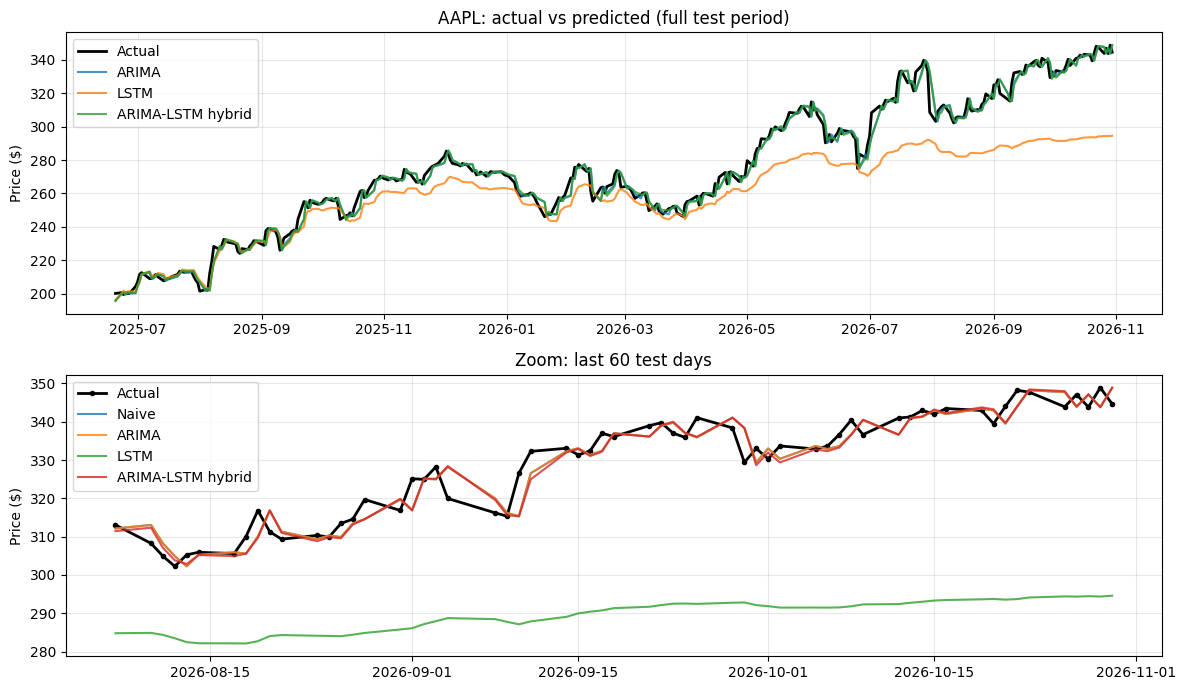

In [9]:
table = pd.DataFrame(results).set_index("Model").round(3)
display(table)

best_name = table["RMSE ($)"].idxmin()
base_rmse = table.loc["Naive (yesterday's price)", "RMSE ($)"]
print(f"Lowest RMSE: {best_name} ({table.loc[best_name, 'RMSE ($)']:.3f}) vs naive baseline ({base_rmse:.3f})")

preds = {
    "Naive": naive_pred,
    "ARIMA": arima_pred,
    "LSTM": lstm_pred,
    "ARIMA-LSTM hybrid": hybrid_pred,
}
test_dates = dates[test_idx]

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
axes[0].plot(test_dates, y_true, color="black", linewidth=2, label="Actual")
for name, p in preds.items():
    if name != "Naive":
        axes[0].plot(test_dates, p, alpha=0.8, label=name)
axes[0].set_title(f"{TICKER}: actual vs predicted (full test period)")
axes[0].set_ylabel("Price ($)"); axes[0].legend(); axes[0].grid(alpha=0.3)

last = 60
axes[1].plot(test_dates[-last:], y_true[-last:], color="black", linewidth=2, marker="o", markersize=3, label="Actual")
for name, p in preds.items():
    axes[1].plot(test_dates[-last:], p[-last:], alpha=0.8, label=name)
axes[1].set_title(f"Zoom: last {last} test days")
axes[1].set_ylabel("Price ($)"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# RMSE bars
axes[0].bar(table.index, table["RMSE ($)"], color=["gray", "tab:blue", "tab:orange", "tab:green"])
axes[0].set_title("Test RMSE (lower is better)")
axes[0].set_ylabel("RMSE ($)")
axes[0].tick_params(axis="x", rotation=20)
for i, v in enumerate(table["RMSE ($)"]):
    axes[0].text(i, v, f"{v:.2f}", ha="center", va="bottom")

# absolute error over time
for name, p in preds.items():
    axes[1].plot(test_dates, np.abs(y_true - p), alpha=0.7, label=name)
axes[1].set_title("Absolute error over the test period")
axes[1].set_ylabel("|Error| ($)"); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].plot(lstm_hist["train"], label="Train"); axes[0].plot(lstm_hist["val"], label="Validation")
axes[0].set_title("LSTM (price) loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("MSE (scaled)")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(res_hist["train"], label="Train"); axes[1].plot(res_hist["val"], label="Validation")
axes[1].set_title("Residual LSTM loss"); axes[1].set_xlabel("Epoch")
axes[1].legend(); axes[1].grid(alpha=0.3)

actual_resid = y_true - arima_pred
axes[2].plot(test_dates, actual_resid, label="Actual ARIMA residual", alpha=0.7)
axes[2].plot(test_dates, resid_pred, label="LSTM-predicted residual", alpha=0.8)
axes[2].set_title("Can the LSTM predict what ARIMA misses?"); axes[2].legend(); axes[2].grid(alpha=0.3)

plt.tight_layout(); plt.show()

## 9. Next-day forecast

Each model predicts the next trading day after the last date in the data. Treat this as a demo output, not a trading signal.

In [ ]:
next_date = pd.bdate_range(dates[-1], periods=2)[1]

arima_next = float(arima_final.forecast(1)[0])

lstm_next = float(sc_price.inverse_transform(
    predict(lstm_model, p_scaled[-WINDOW:].reshape(1, WINDOW, 1)).reshape(-1, 1))[0, 0])

resid_next = float(sc_res.inverse_transform(
    predict(res_model, r_scaled[-WINDOW:].reshape(1, WINDOW, 1)).reshape(-1, 1))[0, 0])
hybrid_next = arima_next + resid_next

print(f"Last close ({dates[-1].date()}): ${prices[-1]:.2f}")
print(f"Forecast for ~{next_date.date()}:")
print(f"  Naive:             ${prices[-1]:.2f}")
print(f"  ARIMA:             ${arima_next:.2f}")
print(f"  LSTM:              ${lstm_next:.2f}")
print(f"  ARIMA-LSTM hybrid: ${hybrid_next:.2f}")

## 10. Save the trained models (optional, for a Streamlit/Gradio demo)

In [ ]:
torch.save({
    "lstm_state": lstm_model.state_dict(),
    "residual_lstm_state": res_model.state_dict(),
    "price_scaler_mean": sc_price.mean_, "price_scaler_scale": sc_price.scale_,
    "resid_scaler_mean": sc_res.mean_, "resid_scaler_scale": sc_res.scale_,
    "arima_order": order, "window": WINDOW, "hidden": HIDDEN, "layers": LAYERS, "ticker": TICKER,
}, "stock_models.pt")
print("Saved stock_models.pt")